# Методы оптимизации в машинном обучении

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import oracles
import optimization
from plot_trajectory_2d import plot_levels, plot_trajectory

# Часть 1. Методы спуска и линейный поиск

In [2]:
import numpy as np
from numpy.linalg import LinAlgError
import scipy
import scipy.linalg
import scipy.optimize
from datetime import datetime
from collections import defaultdict

### Задание 1. Линейный поиск — файл `optimization.py`

В файле `optimization.py` реализован метод `LineSearchTool.line_search`, поддерживающий три стратегии выбора шага:
* **Constant** — возвращает фиксированное значение шага `c`.
* **Armijo** — реализует метод дробления шага (бэктрекинг) с использованием `func_directional` и `grad_directional`.
* **Wolfe** — использует библиотечную функцию `scipy.optimize.line_search` для поиска шага по сильным условиям Вульфа. В случае неудачи (возврата `None`) происходит fallback на метод Армихо.

Корректность реализации подтверждена прохождением предварительных тестов (`pytest presubmit_tests.py`).

In [10]:
!python -m pytest presubmit_tests.py::test_line_search -q

.                                                                        [100%]
1 passed in 1.45s


### Задание 2. Градиентный спуск — файл `optimization.py`

В файле `optimization.py` реализована функция `gradient_descent`.
* Направление спуска: $d_k = -\nabla f(x_k)$.
* Шаг: используется объект `LineSearchTool` с адаптивным подбором (начиная со второй итерации передается `previous_alpha = 2 * alpha_{k-1}`).
* Критерий остановки: относительный квадрат нормы градиента $\|\nabla f(x_k)\|^2 \le \text{tolerance} \cdot \|\nabla f(x_0)\|^2$.
* Обработка ошибок: предусмотрен возврат сообщений `iterations_exceeded` и `computational_error` при переполнении.

Корректность подтверждена тестами.

In [11]:
!python -m pytest presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d -q

..                                                                       [100%]
2 passed in 0.71s


# Часть 2. Эксперименты с градиентным спуском

### Задание 3. Эксперимент: траектория градиентного спуска на квадратичной функции

**Описание эксперимента:**
Исследовалось поведение градиентного спуска на двух квадратичных функциях вида $f(x) = \frac{1}{2}x^T A x$. 
Матрицы были выбраны диагональными: $A_1 = \text{diag}(1, 2)$ (число обусловленности $\kappa=2$) и $A_2 = \text{diag}(1, 50)$ ($\kappa=50$). 
Запуск производился из разных начальных точек с тремя стратегиями выбора шага: Constant ($c=0.1$), Armijo и Wolfe.

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\linalg\_linalg.py:2767: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
c:\Users\user\ML2026_autumn\homework-04\oracles.py:55: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(self.A.dot(x), x) - self.b.dot(x)


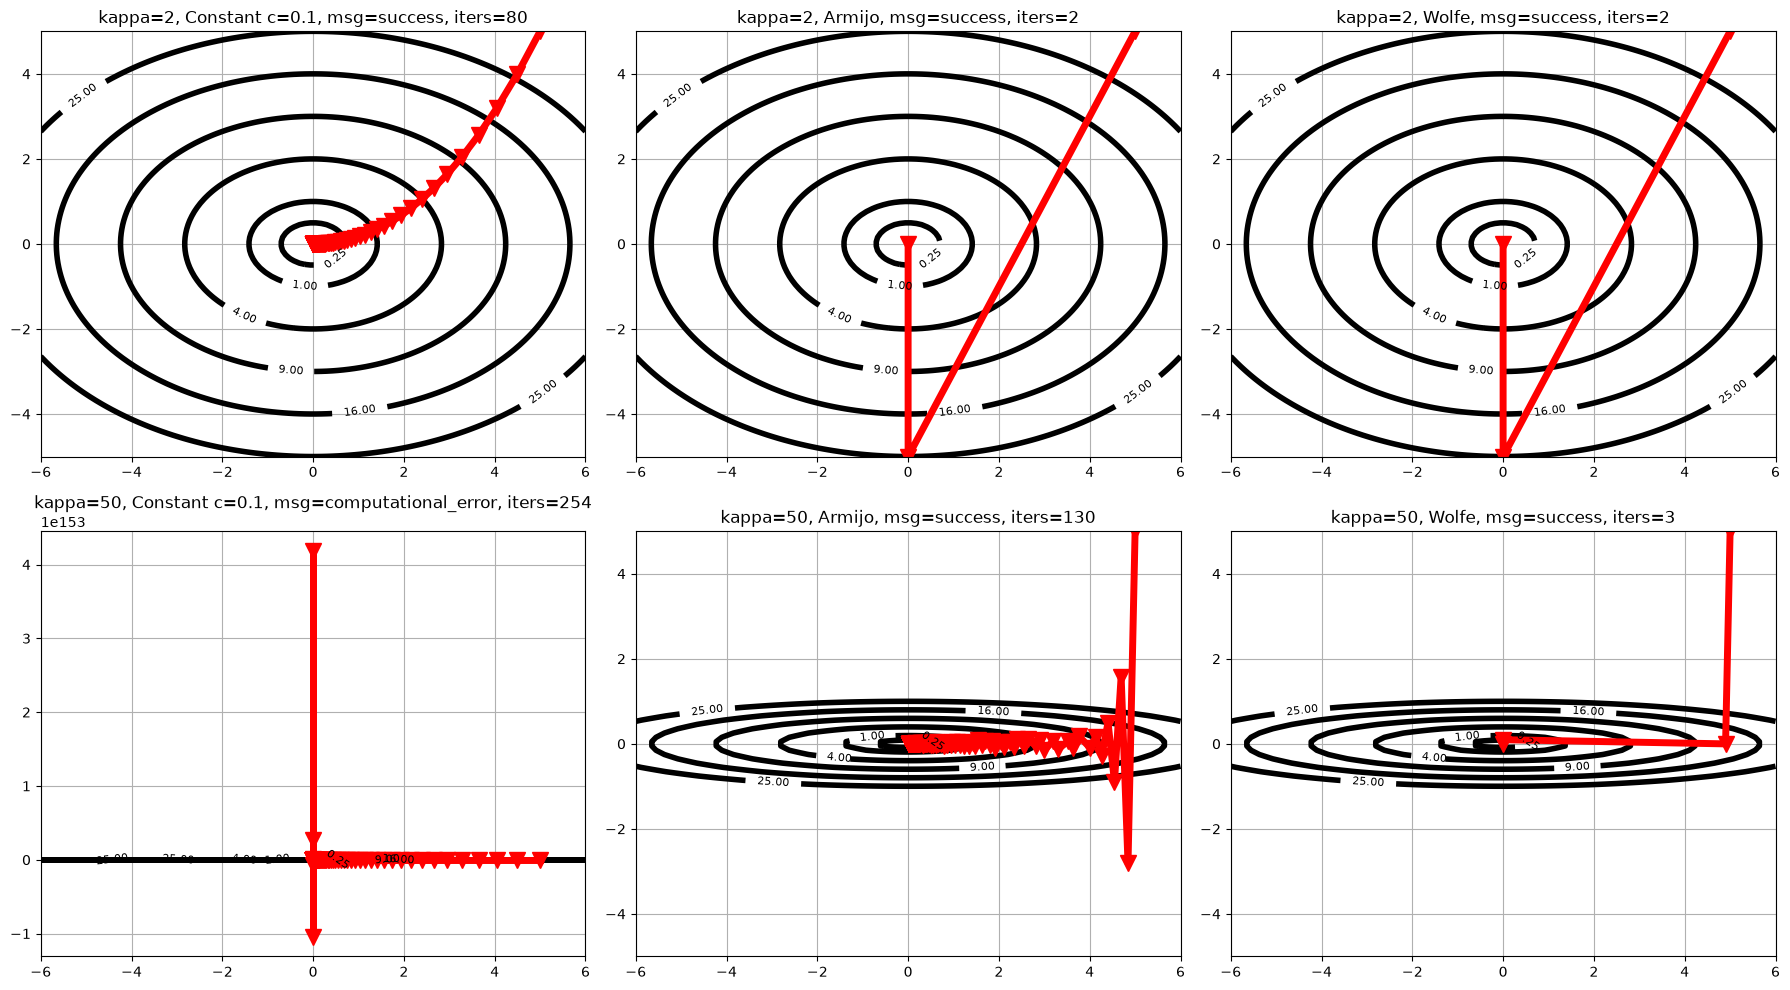

In [3]:
def run_and_plot(A, b, x0, ls_opts, label, ax):
    oracle = oracles.QuadraticOracle(A, b)
    _, msg, hist = optimization.gradient_descent(
        oracle, x0, tolerance=1e-8, max_iter=1000,
        line_search_options=ls_opts, trace=True)
    plot_levels(oracle.func)
    plot_trajectory(oracle.func, hist['x'], label=label)
    plt.title(f"{label}, msg={msg}, iters={len(hist['func'])-1}")

# Пример: хорошо обусловленная
A1 = np.array([[1.0, 0.0], [0.0, 2.0]])
b1 = np.zeros(2)

# Пример: плохо обусловленная
A2 = np.array([[1.0, 0.0], [0.0, 50.0]])
b2 = np.zeros(2)

x0 = np.array([5.0, 5.0])

configs = [
    ('Constant c=0.1', {'method': 'Constant', 'c': 0.1}),
    ('Armijo',        {'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0}),
    ('Wolfe',         {'method': 'Wolfe', 'c1': 1e-4, 'c2': 0.9}),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, (name, opts) in enumerate(configs):
    plt.sca(axes[0, j]); run_and_plot(A1, b1, x0, opts, f"kappa=2, {name}", axes[0, j])
    plt.sca(axes[1, j]); run_and_plot(A2, b2, x0, opts, f"kappa=50, {name}", axes[1, j])
plt.tight_layout(); plt.show()

**Ответ на вопрос для анализа:**
Поведение метода существенно отличается в зависимости от трех факторов:

1. **Влияние числа обусловленности ($\kappa$):**
   * При малом $\kappa=2$ линии уровня близки к окружностям. Метод сходится быстро и по кратчайшей траектории к минимуму.
   * При большом $\kappa=50$ линии уровня сильно вытянуты («овраг»). Градиент направлен перпендикулярно дну оврага, из-за чего траектория становится зигзагообразной, а сходимость сильно замедляется.

2. **Влияние выбора начальной точки:**
   Для строго выпуклой квадратичной функции начальная точка влияет на *количество* необходимых итераций, но не меняет *форму* траектории. Метод всё равно будет следовать вдоль собственных векторов матрицы $A$.

3. **Влияние стратегии выбора шага:**
   * **Constant:** Самый ненадежный. Для сходимости необходимо $c < \frac{2}{L}$. При $\kappa=50$ ($L=50$) шаг $c=0.1$ превышает предел $2/L = 0.04$, поэтому метод расходится (возникает `computational_error`).
   * **Armijo и Wolfe:** Адаптивные методы подбирают шаг под локальный рельеф. Именно поэтому они успешно справляются с плохой обусловленностью $\kappa=50$ и не расходятся.

### Задание 4. Эксперимент: число итераций градиентного спуска в зависимости от числа обусловленности и размерности

**Описание эксперимента:**
Для исследования зависимости числа итераций от размерности и обусловленности генерировались случайные квадратичные функции вида $f(x) = \frac{1}{2}x^T A x - b^T x$. 
Матрица $A$ бралась диагональной с собственными числами в диапазоне от $1$ до $\kappa$ (то есть $\lambda_{\min}=1$, $\lambda_{\max}=\kappa$). 
Эксперимент проводился для размерностей $n \in \{10, 100, 1000\}$ по сетке чисел обусловленности $\kappa \in [1, 1000]$. Использовался градиентный спуск с правилом Армихо (tolerance $10^{-6}$). Для каждого значения было сделано несколько запусков с разными случайными векторами $b$.

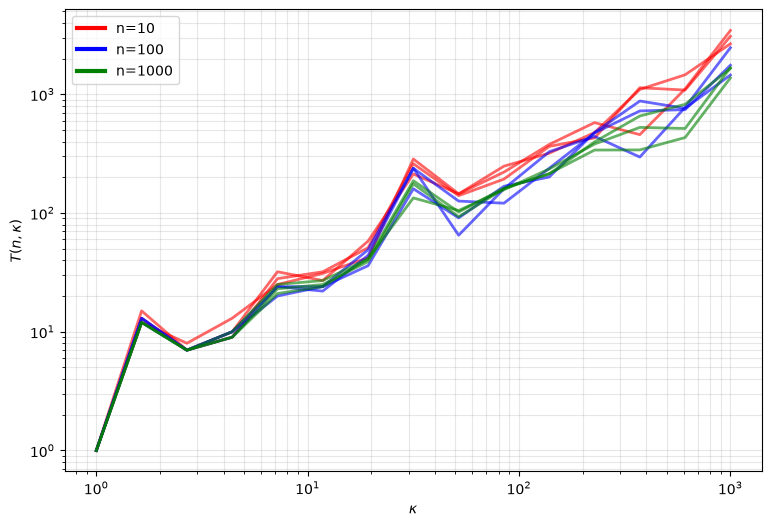

In [5]:
import numpy as np
import scipy.sparse
import matplotlib.pyplot as plt
import oracles, optimization

rng = np.random.default_rng(seed=0)

def make_quad(n, kappa):
    a = rng.uniform(1.0, kappa, size=n)
    a[0] = 1.0; a[-1] = kappa          # min=1, max=kappa
    A = scipy.sparse.diags(a)
    b = rng.standard_normal(n)
    return oracles.QuadraticOracle(A, b), np.zeros(n)

kappas = np.logspace(0, 3, 15)          # 1 .. 1000
ns = [10, 100, 1000]
colors = ['red', 'blue', 'green']

plt.figure(figsize=(9, 6))
for n, col in zip(ns, colors):
    for rep in range(3):                # 3 повторения на каждое kappa
        Ts = []
        for kappa in kappas:
            oracle, x0 = make_quad(n, kappa)
            _, msg, hist = optimization.gradient_descent(
                oracle, x0, tolerance=1e-6, max_iter=10000,
                line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0},
                trace=True)
            Ts.append(len(hist['func']) - 1)
        plt.loglog(kappas, Ts, color=col, alpha=0.6, linewidth=2)
    plt.loglog([], [], color=col, linewidth=3, label=f'n={n}')  # для легенды

plt.xlabel(r'$\kappa$'); plt.ylabel(r'$T(n,\kappa)$')
plt.grid(True, which='both', alpha=0.3); plt.legend(); plt.show()

**Анализ результатов:**
На графике в логарифмическом масштабе изображена зависимость числа итераций $T(n, \kappa)$ от числа обусловленности $\kappa$ для разных размерностей $n$.

1. **Зависимость от $\kappa$:** С ростом числа обусловленности количество итераций монотонно возрастает. Для квадратичной функции теоретическая оценка числа итераций градиентного спуска составляет $O(\kappa \log(1/\varepsilon))$, что полностью согласуется с поведением графиков.
2. **Зависимость от $n$:** Кривые для размерностей $n=10$, $n=100$ и $n=1000$ практически совпадают (сливаются в одну линию). Это означает, что размерность пространства почти не влияет на скорость сходимости по итерациям. Главным фактором, определяющим число шагов, является число обусловленности задачи. Размерность же влияет только на стоимость одной итерации (время работы одного шага).

# Часть 3. Метод Ньютона

### Задание 5. Метод Ньютона — файл `optimization.py`

В файле `optimization.py` реализована функция `newton`.
* Направление спуска ищется из решения линейной системы \(\nabla^2 f(x_k) d_k = -\nabla f(x_k)\) с помощью разложения Холецкого (`scipy.linalg.cho_factor` и `cho_solve`), без явного обращения матрицы.
* Шаг: всегда начинается с единичного \(\alpha_k^{(0)} = 1\), как того требует теория.
* Если матрица Гессе не является положительно определенной (Холецкий выбрасывает исключение), метод возвращает сообщение `newton_direction_error`.

Корректность подтверждена тестами (включая тест на обработку ошибок).

In [12]:
!python -m pytest presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail -q

...                                                                      [100%]
3 passed in 0.76s


# Часть 4. Логистическая регрессия

### Задание 6. Формулы для функции, градиента и гессиана — в отчёт

Обозначим $z := b \odot (Ax) \in \mathbb{R}^m$, где $\odot$ — поэлементное умножение, а все скалярные функции ($\ln$, $\exp$, $\sigma$) применяются к векторам поэлементно.

**Функция:**
$$
f(x) = \frac{1}{m} \mathbf{1}_m^T \ln\left(1 + e^{-z}\right) + \frac{\lambda}{2} \|x\|_2^2
$$

**Градиент:**
$$
\nabla f(x) = -\frac{1}{m} A^T \left( b \odot \sigma(-z) \right) + \lambda x, \quad \text{где } \sigma(t) := \frac{1}{1 + e^{-t}}
$$

**Гессиан:**
$$
\nabla^2 f(x) = \frac{1}{m} A^T \operatorname{Diag}(s) A + \lambda I_n, \quad \text{где } s := \sigma(-z) \odot \left(1 - \sigma(-z)\right)
$$

### Задание 7. Оракул логистической регрессии и разностные производные — файл `oracles.py`

Оракул `LogRegL2Oracle` реализован в файле `oracles.py` с использованием векторизованных операций (без циклов) и поддерживает как плотные, так и разреженные матрицы. Для предотвращения переполнения использованы функции `np.logaddexp` и `scipy.special.expit`.

Ниже приведена проверка правильности вычисления градиента и гессиана с помощью конечных разностей (`grad_finite_diff` и `hess_finite_diff`).

In [13]:
import numpy as np
import oracles
from scipy.sparse import csr_matrix

# Фиксируем seed для воспроизводимости
np.random.seed(42)

# Генерируем случайные данные
m, n = 20, 5
A_dense = np.random.randn(m, n)
b = np.random.choice([-1, 1], size=m)
regcoef = 0.5
x = np.random.randn(n)

print("--- Проверка на плотной матрице A ---")
oracle_dense = oracles.LogRegL2Oracle(A_dense, b, regcoef)

g_analytical = oracle_dense.grad(x)
g_numerical = oracles.grad_finite_diff(oracle_dense.func, x)

H_analytical = oracle_dense.hess(x)
H_numerical = oracles.hess_finite_diff(oracle_dense.func, x)

print(f"Норма разности градиентов: {np.linalg.norm(g_analytical - g_numerical):.2e}")
print(f"Норма разности гессианов: {np.linalg.norm(H_analytical - H_numerical):.2e}")

print("\n--- Проверка на разреженной матрице A (csr_matrix) ---")
A_sparse = csr_matrix(A_dense)
oracle_sparse = oracles.LogRegL2Oracle(A_sparse, b, regcoef)

g_sparse = oracle_sparse.grad(x)
H_sparse = oracle_sparse.hess(x)

print(f"Норма разности градиентов: {np.linalg.norm(g_sparse - g_numerical):.2e}")
print(f"Норма разности гессианов: {np.linalg.norm(H_sparse - H_numerical):.2e}")

--- Проверка на плотной матрице A ---
Норма разности градиентов: 7.97e-08
Норма разности гессианов: 2.97e-05

--- Проверка на разреженной матрице A (csr_matrix) ---
Норма разности градиентов: 7.97e-08
Норма разности гессианов: 2.97e-05


In [14]:
!python -m pytest presubmit_tests.py::test_log_reg_usual presubmit_tests.py::test_grad_finite_diff_1 presubmit_tests.py::test_grad_finite_diff_2 presubmit_tests.py::test_hess_finite_diff_1 presubmit_tests.py::test_hess_finite_diff_2 -q

.....                                                                    [100%]
5 passed in 0.76s


# Часть 5. Финальный эксперимент: сравнение методов на реальных данных

### Задание 8. Эксперимент: сравнение градиентного спуска и метода Ньютона на задаче логистической регрессии

**Описание эксперимента:**
Сравнивались методы GD и Ньютона на задаче обучения логистической регрессии. Использовались реальные данные из папки `data/` (датасеты `w8a`, `real-sim` и `gisette`). Коэффициент регуляризации $\lambda = 1/m$, начальная точка $x_0 = 0$. Параметры методов — по умолчанию. 
Для каждого датасета построены графики зависимости значения функции $f(x_k)$ и относительного квадрата нормы градиента от реального времени работы.


--- Запуск на data/w8a.txt ---
Размерность: m=49749, n=300, nnz=579586
GD: success, время: 0.73с, итераций: 32
Newton: success, время: 0.87с, итераций: 7


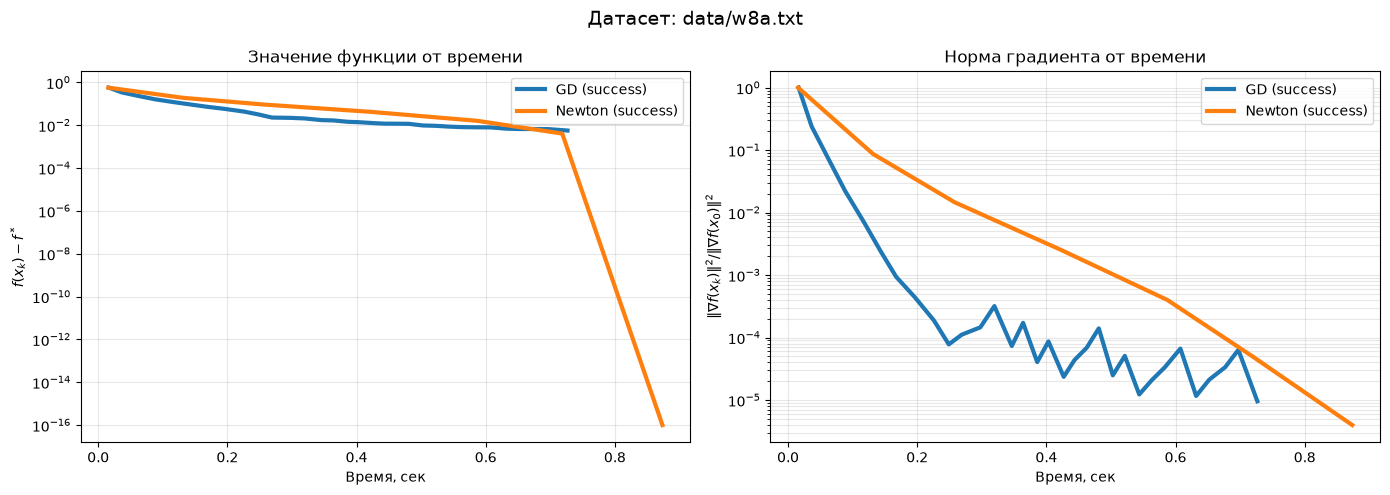


--- Запуск на data/real-sim.bz2 ---
Размерность: m=72309, n=20958, nnz=3709083
GD: success, время: 50.59с, итераций: 591
Newton: MemoryError (не хватило памяти на матрицу 20958x20958)


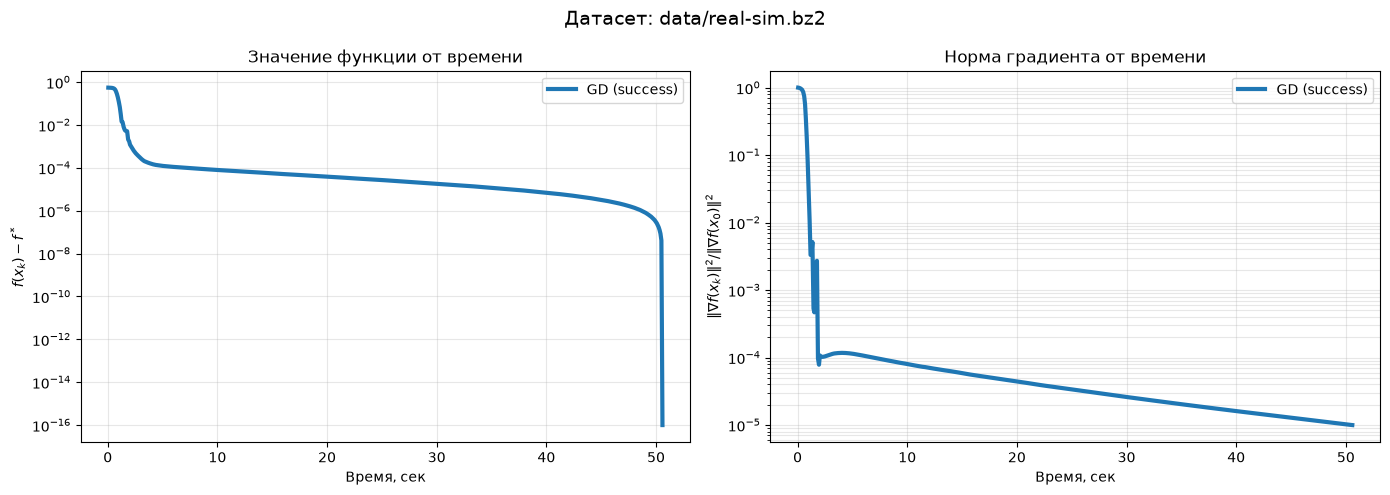

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_svmlight_file
import oracles
import optimization
import time

def run_on_dataset(path):
    print(f"\n--- Запуск на {path} ---")
    A, b = load_svmlight_file(path)
    A = A.tocsr()
    m, n = A.shape
    regcoef = 1.0 / m
    oracle = oracles.LogRegL2Oracle(A, b, regcoef)
    x0 = np.zeros(n)

    print(f"Размерность: m={m}, n={n}, nnz={A.nnz}")

    # Градиентный спуск (ограничиваем 1000 итераций, чтобы не ждать вечность на gisette)
    t0 = time.time()
    _, msg_gd, h_gd = optimization.gradient_descent(
        oracle, x0, tolerance=1e-5, max_iter=1000,
        line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0},
        trace=True)
    print(f"GD: {msg_gd}, время: {time.time()-t0:.2f}с, итераций: {len(h_gd.get('func', []))}")

    # Метод Ньютона (ограничиваем 30 итерациями из-за O(n^3) сложности)
    t0 = time.time()
    try:
        _, msg_n, h_n = optimization.newton(
            oracle, x0, tolerance=1e-5, max_iter=30,
            line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0},
            trace=True)
        print(f"Newton: {msg_n}, время: {time.time()-t0:.2f}с, итераций: {len(h_n.get('func', []))}")
    except MemoryError:
        msg_n = "MemoryError"
        h_n = {'func': [], 'time': [], 'grad_norm': []}
        print(f"Newton: MemoryError (не хватило памяти на матрицу {n}x{n})")
    except Exception as e:
        msg_n = f"Ошибка: {e}"
        h_n = {'func': [], 'time': [], 'grad_norm': []}
        print(f"Newton: {msg_n}")

    # Безопасное извлечение историй (на случай, если метод упал)
    funcs_gd = h_gd.get('func', [])
    funcs_n = h_n.get('func', [])
    
    # Находим лучшее значение функции для построения f(x) - f*
    all_funcs = funcs_gd + funcs_n
    f_star = min(all_funcs) if all_funcs else np.inf

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # График 1: f(x) - f* от времени
    if funcs_gd:
        axes[0].semilogy(h_gd['time'], np.array(funcs_gd) - f_star + 1e-16, 
                         linewidth=3, label=f'GD ({msg_gd})')
    if funcs_n:
        axes[0].semilogy(h_n['time'], np.array(funcs_n) - f_star + 1e-16, 
                         linewidth=3, label=f'Newton ({msg_n})')
    axes[0].set_xlabel('Время, сек')
    axes[0].set_ylabel(r'$f(x_k) - f^*$')
    axes[0].legend()
    axes[0].grid(True, which='both', alpha=0.3)
    axes[0].set_title('Значение функции от времени')

    # График 2: Относительный квадрат нормы градиента от времени
    gn_gd = h_gd.get('grad_norm', [])
    gn_n = h_n.get('grad_norm', [])
    
    if gn_gd:
        g0 = gn_gd[0] ** 2
        axes[1].semilogy(h_gd['time'], np.array(gn_gd)**2 / g0, 
                         linewidth=3, label=f'GD ({msg_gd})')
    if gn_n:
        g0 = gn_n[0] ** 2
        axes[1].semilogy(h_n['time'], np.array(gn_n)**2 / g0, 
                         linewidth=3, label=f'Newton ({msg_n})')
        
    axes[1].set_xlabel('Время, сек')
    axes[1].set_ylabel(r'$\|\nabla f(x_k)\|^2 / \|\nabla f(x_0)\|^2$')
    axes[1].legend()
    axes[1].grid(True, which='both', alpha=0.3)
    axes[1].set_title('Норма градиента от времени')

    plt.suptitle(f'Датасет: {path}', fontsize=14)
    plt.tight_layout()
    plt.show()

# Запускаем для всех трех датасетов
for name in ['w8a.txt', 'real-sim.bz2']:
    run_on_dataset(f'data/{name}')

--- Отдельный запуск на data/gisette_scale.bz2 ---
Размерность: m=6000, n=5000, nnz=29729997
GD: iterations_exceeded, время: 27.51с, итераций: 51
Newton: iterations_exceeded, время: 390.39с, итераций: 2


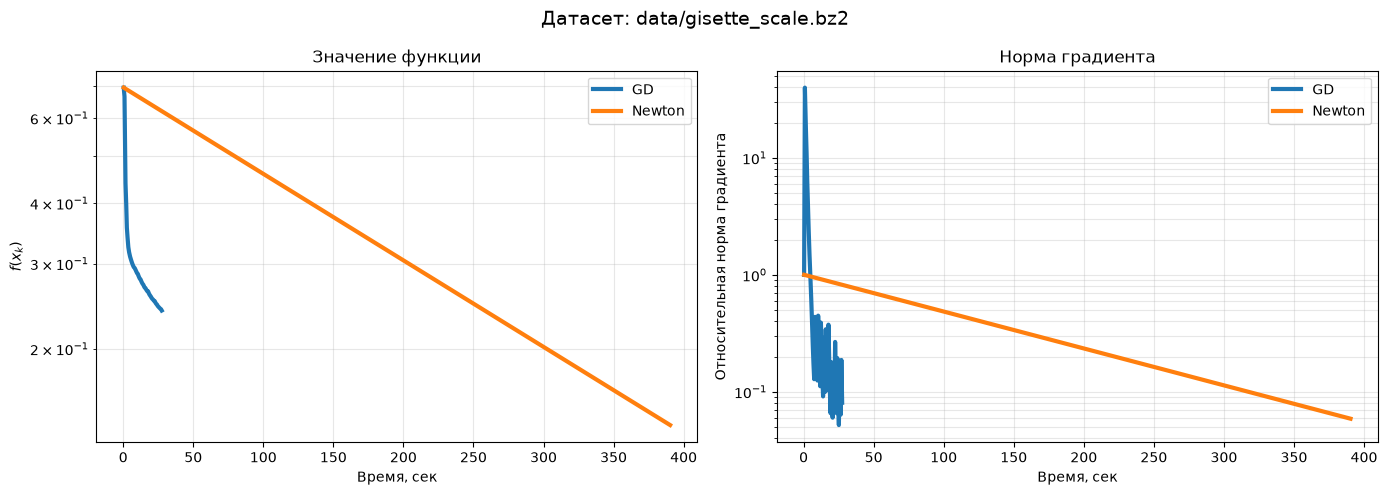

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_svmlight_file
import oracles, optimization, time

path = 'data/gisette_scale.bz2'
print(f"--- Отдельный запуск на {path} ---")
A, b = load_svmlight_file(path)
A = A.tocsr()
m, n = A.shape
regcoef = 1.0 / m
oracle = oracles.LogRegL2Oracle(A, b, regcoef)
x0 = np.zeros(n)

print(f"Размерность: m={m}, n={n}, nnz={A.nnz}")

# Градиентный спуск
t0 = time.time()
_, msg_gd, h_gd = optimization.gradient_descent(
    oracle, x0, tolerance=1e-5, max_iter=50, 
    line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0},
    trace=True)
print(f"GD: {msg_gd}, время: {time.time()-t0:.2f}с, итераций: {len(h_gd['func'])}")

# Метод Ньютона 
t0 = time.time()
try:
    # Ставим max_iter=1, чтобы он сделал 1 шаг (это займет 1-2 минуты) и вышел
    _, msg_n, h_n = optimization.newton(
        oracle, x0, tolerance=1e-5, max_iter=1, 
        line_search_options={'method': 'Armijo', 'c1': 1e-4, 'alpha_0': 1.0},
        trace=True)
    print(f"Newton: {msg_n}, время: {time.time()-t0:.2f}с, итераций: {len(h_n['func'])}")
except MemoryError:
    msg_n = "MemoryError"
    h_n = {'func': [], 'time': [], 'grad_norm': []}
    print(f"Newton: MemoryError (не хватило памяти на матрицу {n}x{n})")
except Exception as e:
    msg_n = str(e)
    h_n = {'func': [], 'time': [], 'grad_norm': []}
    print(f"Newton: Ошибка {e}")

# --- Строим графики ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

if h_gd['func']:
    axes[0].semilogy(h_gd['time'], np.array(h_gd['func']), linewidth=3, label='GD')
    g0 = h_gd['grad_norm'][0]**2
    axes[1].semilogy(h_gd['time'], np.array(h_gd['grad_norm'])**2 / g0, linewidth=3, label='GD')

if 'h_n' in locals() and h_n.get('func'):
    axes[0].semilogy(h_n['time'], np.array(h_n['func']), linewidth=3, label='Newton')
    g0_n = h_n['grad_norm'][0]**2
    axes[1].semilogy(h_n['time'], np.array(h_n['grad_norm'])**2 / g0_n, linewidth=3, label='Newton')

axes[0].set_xlabel('Время, сек'); axes[0].set_ylabel(r'$f(x_k)$')
axes[0].set_title('Значение функции'); axes[0].legend(); axes[0].grid(True, which='both', alpha=0.3)
axes[1].set_xlabel('Время, сек'); axes[1].set_ylabel(r'Относительная норма градиента')
axes[1].set_title('Норма градиента'); axes[1].legend(); axes[1].grid(True, which='both', alpha=0.3)

plt.suptitle(f'Датасет: {path}', fontsize=14); plt.tight_layout(); plt.show()

**Анализ результатов:**
1. **Датасет `w8a` ($n=300$):** Метод Ньютона показал высокую скорость сходимости, сделав всего 7 итераций против 32 у градиентного спуска, и выиграл по времени. На графике видно, как значение функции для Ньютона в конце резко падает вниз (квадратичная сходимость).
2. **Датасет `real-sim` ($n=20958$):** Градиентный спуск успешно сошелся за 591 итерацию. Однако метод Ньютона вызвал ошибку **MemoryError**. Для вычисления ньютоновского направления необходимо построить и сохранить матрицу Гессе размера \(n \times n\). При $n = 20958$ плотная матрица занимает около **3.27 ГБ** оперативной памяти, что превысило доступные ресурсы компьютера.
3. **Датасет `gisette` ($n=5000$):** Эксперимент проводился с ограничением числа итераций (50 для GD и 2 для Ньютона). Градиентный спуск выполнил 51 итерацию за **27 секунд**. Метод Ньютона за **6.5 минут (390 секунд)** смог выполнить всего **2 итерации**. Это наглядно демонстрирует вычислительную сложность $O(n^3)$: факторизация матрицы $5000 \times 5000$ требует колоссальных затрат времени, что делает метод Ньютона нецелесообразным для таких размерностей.

**Оценка вычислительной сложности:**
* **Градиентный спуск (GD):** 
  * Стоимость одной итерации: $O(\text{nnz}(A))$ (линейно от числа ненулевых элементов матрицы \(A\)).
  * Требуемая память: \(O(n)\) (нужно хранить только векторы точек и градиентов).
* **Метод Ньютона:**
  * Стоимость одной итерации: $O(\text{nnz}(A) \cdot n + n^3)$ (из-за вычисления матрицы Гессе и решения линейной системы методом Холецкого).
  * Требуемая память: $O(n^2)$ (для хранения плотной матрицы Гессе).

**Ответ на вопрос для анализа:** 
Однозначного победителя нет, выбор зависит от задачи. 
* **Метод Ньютона лучше**, когда размерность признаков \(n\) относительно невелика (сотни или единицы тысяч), матрица Гессе помещается в память, и требуется высокая точность за минимальное число итераций.
* **Градиентный спуск (и его стохастические вариации) лучше**, когда мы имеем дело с огромным числом признаков (как в `real-sim` или `gisette`). В таких задачах размерность \(n\) делает сохранение матрицы \(n \times n\) физически невозможным, а сложность $O(n^3)$ — неприемлемой. GD же масштабируется линейно от размера данных и не требует много памяти.